# 03 · Nasdaq TotalView-ITCH: parsing e ricostruzione MBO

Si usano i sette file giornalieri pubblici Nasdaq ITCH 5.0 completi (3,5-5,6 GB compressi ciascuno). Ogni file contiene tutti i messaggi dalla mezzanotte, quindi il book di apertura si ricostruisce interamente dai messaggi. La finestra analizzata è la **sessione regolare completa, 09:30-16:00**: il parser smette di decomprimere alla chiusura e scarta la negoziazione after-hours.

Il parser decomprime il flusso a blocchi, legge solo il tipo e lo *stock locate* di ogni messaggio e decodifica i messaggi `A/F/E/C/X/D/U` dei titoli richiesti (AAPL, MSFT, INTC). Gli eventi precedenti alle 09:30 sono marcati *bootstrap*: ricostruiscono il book ma non attivano la strategia. Gli eventi sono scritti in Parquet a blocchi, partizionati per sessione e titolo, senza tenere in memoria la giornata intera.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
ingest = R.load_json(ROOT, "ingest/itch")["sessions"]
table = pd.DataFrame([{"sessione": s["session"], "messaggi (milioni)": s["messages"] / 1e6,
                       "ultimo messaggio letto": s["coverage_end"][:8], **{f"eventi {k}": v for k, v in s["rows"].items()},
                       "secondi": s["seconds"], "messaggi/s (migliaia)": s["messages_per_second"] / 1e3} for s in ingest])
display(table.round(1))
print(f"Throughput medio del parser: {it(table['messaggi/s (migliaia)'].mean())} mila messaggi al secondo per processo")

,sessione,messaggi (milioni),ultimo messaggio letto,eventi AAPL,eventi MSFT,eventi INTC,secondi,messaggi/s (migliaia)
0,2019-01-30,367.0,16:02:38,1653277,1600176,1161669,276.4,1327.9
1,2019-03-27,419.9,16:00:00,1966458,2113745,1404955,311.9,1346.2
2,2019-07-30,280.3,16:00:01,1231999,1198918,811546,209.8,1336.4
3,2019-08-30,309.0,16:00:02,1190065,1552841,970055,234.0,1320.6
4,2019-10-30,291.1,16:00:00,734884,1210066,919429,218.8,1330.2
5,2019-12-30,267.1,16:00:01,1485761,1193969,742360,203.0,1316.1
6,2020-01-30,419.3,16:00:00,1960587,1798035,1587095,312.9,1339.9


Throughput medio del parser: 1.331 mila messaggi al secondo per processo


## Controlli di qualità

Il flusso di ogni sessione viene riprodotto nel book: timestamp decrescenti, quantità non positive, riduzioni su Order ID mai visti, ADD duplicati, esecuzioni oltre il residuo e record con book incrociato devono essere assenti.

In [2]:
quality = R.load(ROOT, "quality").query("dataset == 'itch'")
cols = ["events", "bootstrap_events", "records", "ts_decreasing", "nonpositive_size", "unknown_order",
        "duplicate_add", "overfill", "crossed"]
display(quality.set_index(["session", "symbol"])[cols])
anomalies = quality[["ts_decreasing", "nonpositive_size", "unknown_order", "duplicate_add", "overfill", "crossed"]].sum()
assert anomalies.sum() == 0, anomalies
print(f"{it(quality.records.sum())} record di negoziazione in {len(quality)} sessioni, nessuna anomalia")

events  bootstrap_events  records  ts_decreasing  \
session    symbol                                                        
2019-01-30 AAPL    1611688.0           25163.0  1586525              0   
           INTC    1150262.0             622.0  1149640              0   
           MSFT    1578556.0            9102.0  1569454              0   
2019-03-27 AAPL    1966197.0           12260.0  1953937              0   
           INTC    1404772.0             185.0  1404587              0   
           MSFT    2113579.0            4125.0  2109454              0   
2019-07-30 AAPL    1215442.0            8970.0  1206472              0   
           INTC     797977.0            1349.0   796628              0   
           MSFT    1186628.0            3321.0  1183307              0   
2019-08-30 AAPL    1152772.0           11440.0  1141332              0   
           INTC     955493.0             849.0   954644              0   
           MSFT    1529913.0            3287.0  1526626              0   
2019-10-30 AAPL     734781.0            7434.0   727347              0   
           INTC     919295.0             410.0   918885              0   
           MSFT    1209919.0            3128.0  1206791              0   
2019-12-30 AAPL    1484333.0            7091.0  1477242              0   
           INTC     740867.0             298.0   740569              0   
           MSFT    1192522.0            4423.0  1188099              0   
2020-01-30 AAPL    1960340.0           17851.0  1942489              0   
           INTC    1586789.0             649.0  1586140              0   
           MSFT    1797838.0           21341.0  1776497              0   

                   nonpositive_size  unknown_order  duplicate_add  overfill  \
session    symbol                                                             
2019-01-30 AAPL                   0            0.0            0.0       0.0   
           INTC                   0            0.0            0.0       0.0   
           MSFT                   0            0.0            0.0       0.0   
2019-03-27 AAPL                   0            0.0            0.0       0.0   
           INTC                   0            0.0            0.0       0.0   
           MSFT                   0            0.0            0.0       0.0   
2019-07-30 AAPL                   0            0.0            0.0       0.0   
           INTC                   0            0.0            0.0       0.0   
           MSFT                   0            0.0            0.0       0.0   
2019-08-30 AAPL                   0            0.0            0.0       0.0   
           INTC                   0            0.0            0.0       0.0   
           MSFT                   0            0.0            0.0       0.0   
2019-10-30 AAPL                   0            0.0            0.0       0.0   
           INTC                   0            0.0            0.0       0.0   
           MSFT                   0            0.0            0.0       0.0   
2019-12-30 AAPL                   0            0.0            0.0       0.0   
           INTC                   0            0.0            0.0       0.0   
           MSFT                   0            0.0            0.0       0.0   
2020-01-30 AAPL                   0            0.0            0.0       0.0   
           INTC                   0            0.0            0.0       0.0   
           MSFT                   0            0.0            0.0       0.0   

                   crossed  
session    symbol           
2019-01-30 AAPL          0  
           INTC          0  
           MSFT          0  
2019-03-27 AAPL          0  
           INTC          0  
           MSFT          0  
2019-07-30 AAPL          0  
           INTC          0  
           MSFT          0  
2019-08-30 AAPL          0  
           INTC          0  
           MSFT          0  
2019-10-30 AAPL          0  
           INTC          0  
           MSFT          0  
2019-12-

28.146.665 record di negoziazione in 21 sessioni, nessuna anomalia


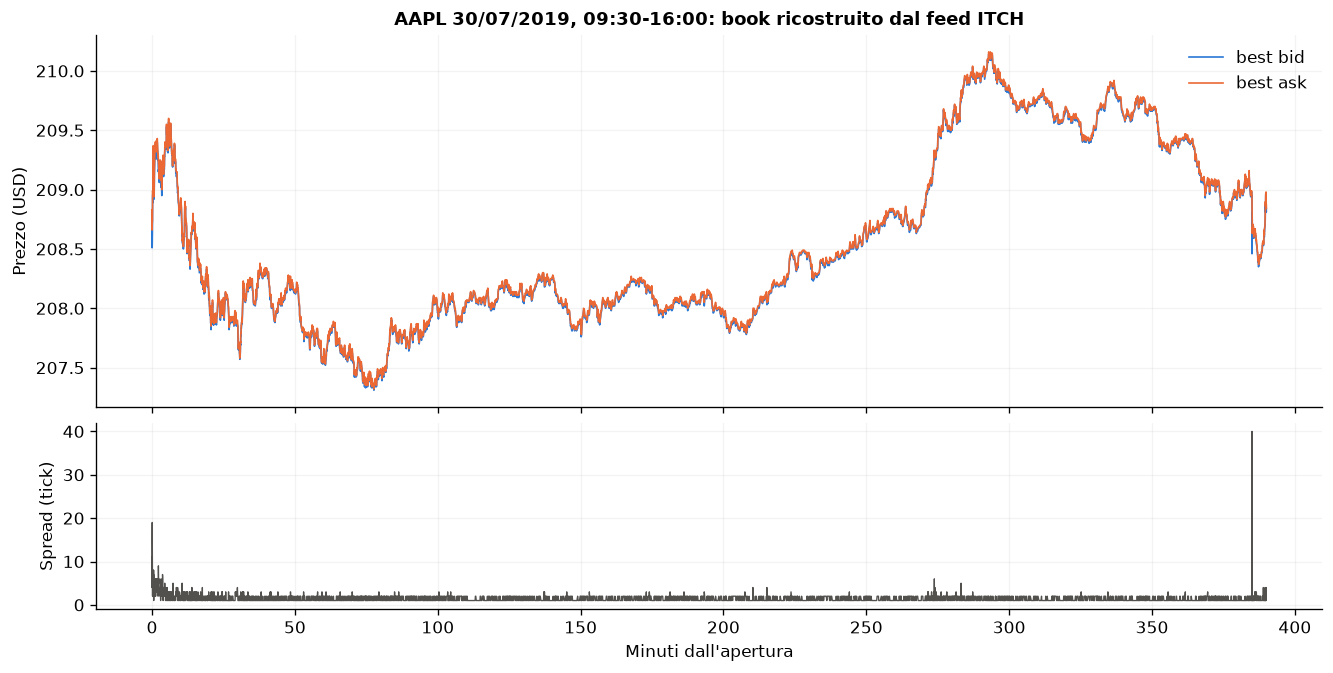

Spread di un tick nel 56,1% dei record; profondità mediana al best 230 azioni (bid) e 235 (ask).

In [3]:
from market_making_tesi import storage
from market_making_tesi.pipeline import DATASETS, events, l2_view, session_list
spec = DATASETS["itch"]
path = next(p for s, sym, p in session_list(ROOT, spec) if s == "2019-07-30" and sym == "AAPL")
view = pd.DataFrame([(s.timestamp, s.best_bid, s.best_ask, s.bid_sizes[0], s.ask_sizes[0])
                     for s in l2_view(events(spec, path, "AAPL"))], columns=["ts", "bid", "ask", "bid_sz", "ask_sz"])
view["time"] = pd.to_datetime(view.ts, unit="ns").dt.time
step = max(1, len(view) // 4000)
v = view.iloc[::step]
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, layout="constrained", gridspec_kw={"height_ratios": [2, 1]})
x = (v.ts - v.ts.iloc[0]) / 6e10
axes[0].plot(x, v.bid, color=R.COLORS["touch"], linewidth=1, label="best bid")
axes[0].plot(x, v.ask, color=R.COLORS["price-through"], linewidth=1, label="best ask")
axes[0].set(title="AAPL 30/07/2019, 09:30-16:00: book ricostruito dal feed ITCH", ylabel="Prezzo (USD)")
axes[0].legend(frameon=False)
axes[1].plot(x, ((v.ask - v.bid) / 0.01).round(), color=R.INK, linewidth=0.8)
axes[1].set(xlabel="Minuti dall'apertura", ylabel="Spread (tick)")
fig.savefig(FIGURES / "itch_book_aapl.png", dpi=180, bbox_inches="tight")
plt.show()
display(Markdown(f"Spread di un tick nel {pct(((view.ask - view.bid) < 0.0101).mean())} dei record; "
                 f"profondità mediana al best {it(view.bid_sz.median())} azioni (bid) e {it(view.ask_sz.median())} (ask)."))

## Vista L2 dallo stesso feed

Come previsto dal piano, la vista L2 usata da `touch`, `price-through` e `cross` è ricostruita **dallo stesso feed** order-level, record per record: i quattro modelli osservano lo stesso periodo, lo stesso strumento e la stessa sequenza di stati del book.